# **Crowd Prediction**

In [11]:
import numpy as np 
import pandas as pd 

In [13]:
data = pd.read_csv('/kaggle/input/datasets/dheerajsingh28b/time-series-footfalls-uttrakhand/time-series-footfalls.csv')

In [14]:
data.head()

,year,month,season,destination,district,category,domestic_visitors,foreign_visitors,total_footfall,is_festival_month,public_holidays_and_long_weekends,avg_temp_c,avg_rainfall_mm,crowd_level
0,2022,January,Moderate,Nainital Lake,Nainital,Hill Station / Lake Tourism,36713,799,37512,0,2,6.8,52,High
1,2022,February,Moderate,Nainital Lake,Nainital,Hill Station / Lake Tourism,45989,1384,47373,0,1,9.3,38,High
2,2022,March,Moderate,Nainital Lake,Nainital,Hill Station / Lake Tourism,42499,1241,43740,1,2,13.3,44,High
3,2022,April,Moderate,Nainital Lake,Nainital,Hill Station / Lake Tourism,41281,1062,42343,0,2,19.2,23,High
4,2022,May,Peak,Nainital Lake,Nainital,Hill Station / Lake Tourism,77089,1741,78830,0,1,20.7,70,Very High


In [15]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 288 entries, 0 to 287
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   year                               288 non-null    int64  
 1   month                              288 non-null    object 
 2   season                             288 non-null    object 
 3   destination                        288 non-null    object 
 4   district                           288 non-null    object 
 5   category                           288 non-null    object 
 6   domestic_visitors                  288 non-null    int64  
 7   foreign_visitors                   288 non-null    int64  
 8   total_footfall                     288 non-null    int64  
 9   is_festival_month                  288 non-null    int64  
 10  public_holidays_and_long_weekends  288 non-null    int64  
 11  avg_temp_c                         288 non-null    float64

In [16]:
data['crowd_level'].value_counts()

crowd_level
Very High    128
Moderate      64
High          51
Low           45
Name: count, dtype: int64

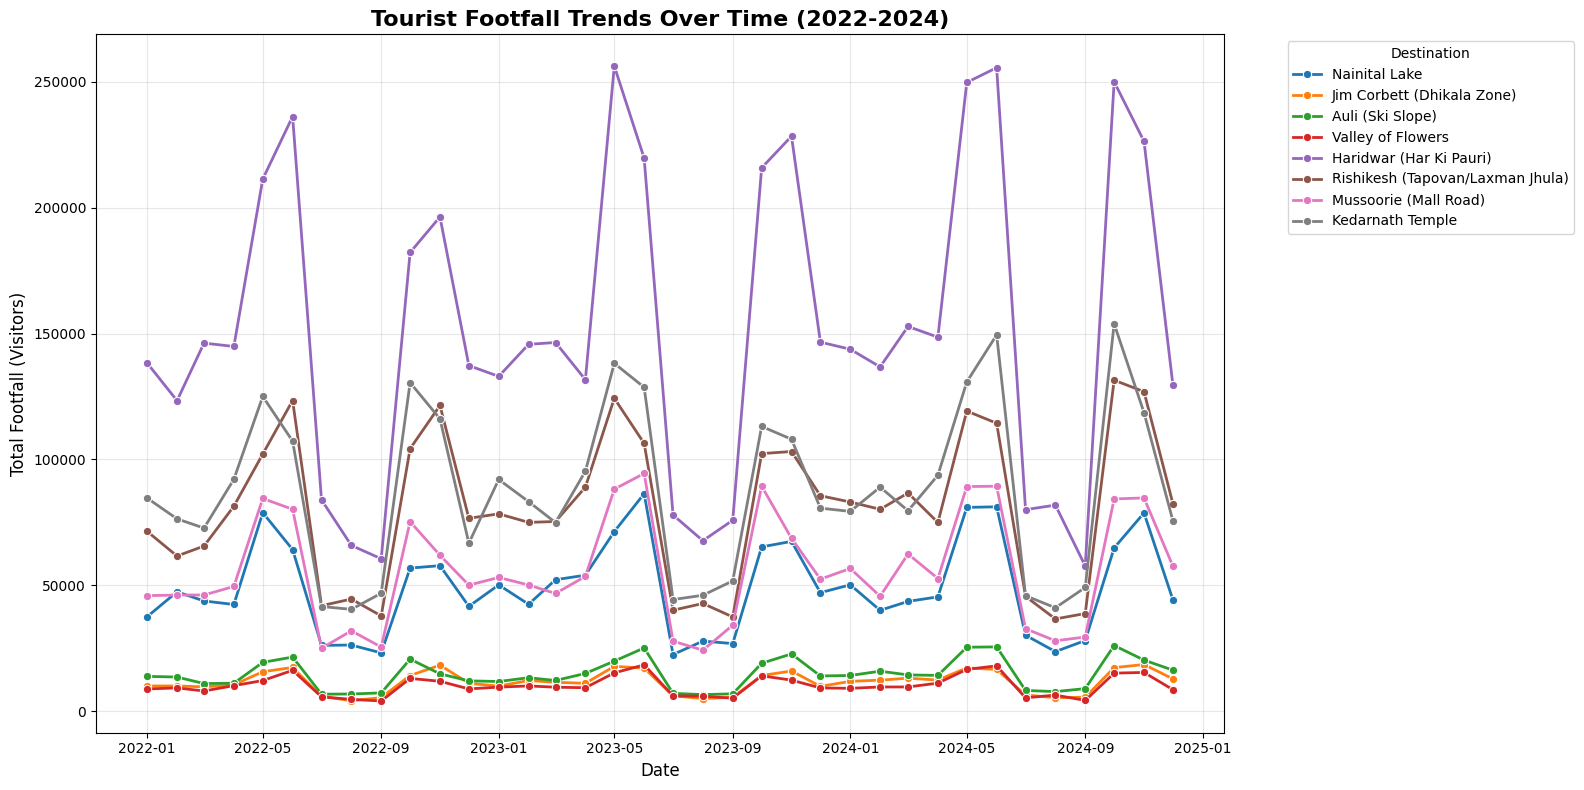

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Convert year and month into a proper datetime column
data['date'] = pd.to_datetime(data['year'].astype(str) + '-' + data['month'].astype(str) + '-01')

# 2. Sort by date for proper time-series plotting
data = data.sort_values('date')

# 3. Plot total_footfall over time for each destination
plt.figure(figsize=(16, 8))
sns.lineplot(data=data, x='date', y='total_footfall', hue='destination', marker='o', linewidth=2)

plt.title('Tourist Footfall Trends Over Time (2022-2024)', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Total Footfall (Visitors)', fontsize=12)
plt.legend(title='Destination', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


/tmp/ipykernel_50/2330912890.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=monthly_avg.index, y=monthly_avg.values, palette='viridis')


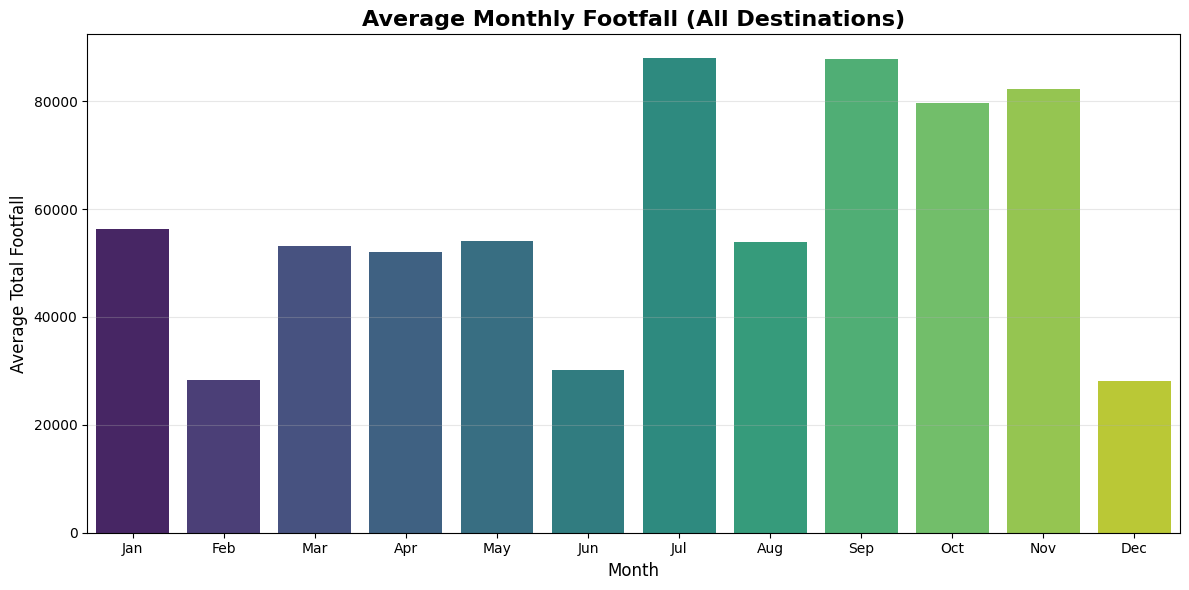

In [20]:

# 4. Plot seasonal patterns (average footfall by month across all destinations)
plt.figure(figsize=(12, 6))
monthly_avg = data.groupby('month')['total_footfall'].mean()
sns.barplot(x=monthly_avg.index, y=monthly_avg.values, palette='viridis')

plt.title('Average Monthly Footfall (All Destinations)', fontsize=16, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Average Total Footfall', fontsize=12)
plt.xticks(range(12), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

In [21]:
print("✅ Time-Series Visualization Complete!")
print(f"\n📊 Data Summary:")
print(f"   - Date Range: {data['date'].min().strftime('%Y-%m')} to {data['date'].max().strftime('%Y-%m')}")
print(f"   - Total Destinations: {data['destination'].nunique()}")
print(f"   - Average Monthly Footfall: {data['total_footfall'].mean():,.0f} visitors")

✅ Time-Series Visualization Complete!

📊 Data Summary:
   - Date Range: 2022-01 to 2024-12
   - Total Destinations: 8
   - Average Monthly Footfall: 57,819 visitors


# **Time Series Forecasting With Facebook Prophet**

In [22]:
# 1. Install Prophet (Kaggle doesn't have it pre-installed)
!pip install prophet --quiet

In [23]:
# 2. Import Prophet
from prophet import Prophet

In [24]:
# 3. Prepare data for ONE destination first (Nainital Lake)
# Prophet requires columns named 'ds' (date) and 'y' (value to forecast)
nainital_data = data[data['destination'] == 'Nainital Lake'][['date', 'total_footfall']].copy()
nainital_data.columns = ['ds', 'y']

# 4. Sort by date (Prophet requires chronological order)
nainital_data = nainital_data.sort_values('ds')

In [25]:
# 5. Verify the data
print("✅ Nainital Data Ready for Prophet!")
print(f"   - Rows: {len(nainital_data)}")
print(f"   - Date Range: {nainital_data['ds'].min()} to {nainital_data['ds'].max()}")
print(f"   - Footfall Range: {nainital_data['y'].min():,} to {nainital_data['y'].max():,}")
print("\n📊 First 5 rows:")
print(nainital_data.head())

✅ Nainital Data Ready for Prophet!
   - Rows: 36
   - Date Range: 2022-01-01 00:00:00 to 2024-12-01 00:00:00
   - Footfall Range: 22,465 to 86,363

📊 First 5 rows:
          ds      y
0 2022-01-01  37512
1 2022-02-01  47373
2 2022-03-01  43740
3 2022-04-01  42343
4 2022-05-01  78830


In [26]:
# 1. Initialize the Prophet Model
# We use default settings for now to establish a baseline
model = Prophet(yearly_seasonality=True, weekly_seasonality=False)

# 2. Train (Fit) the model on our historical data
print("🧠 Training Prophet Model on Nainital Data (2022-2024)...")
model.fit(nainital_data)

04:46:03 - cmdstanpy - INFO - Chain [1] start processing


🧠 Training Prophet Model on Nainital Data (2022-2024)...


04:46:04 - cmdstanpy - INFO - Chain [1] done processing


In [27]:
# 3. Create a dataframe for future dates
# We want to predict the next 12 months. 'MS' means 'Month Start' frequency.
future = model.make_future_dataframe(periods=12, freq='MS')

In [28]:
# 4. Generate the forecast
print("🔮 Predicting future footfall for 2025...")
forecast = model.predict(future)

🔮 Predicting future footfall for 2025...


5. Display the last 15 rows (Last 3 months of 2024 + 12 months of 2025 forecast)
- 📊 Forecast Results (Last 3 historical + 12 future months)

In [30]:
forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail(15)

,ds,yhat,yhat_lower,yhat_upper
33,2024-10-01,64405.734801,60193.574918,68436.868310
34,2024-11-01,76680.341100,72612.249496,80674.101536
35,2024-12-01,43812.039075,39961.383414,47936.900472
36,2025-01-01,45898.898612,41549.141765,49713.398882
37,2025-02-01,64578.897809,60765.739417,68764.149645
38,2025-03-01,50921.224240,46908.535953,55102.739864
39,2025-04-01,52150.292288,48128.156889,56233.950762
40,2025-05-01,85558.726437,81373.123874,89778.448100
41,2025-06-01,83678.008551,79342.806891,87754.778154
42,2025-07-01,34397.694223,30163.514375,38337.531896


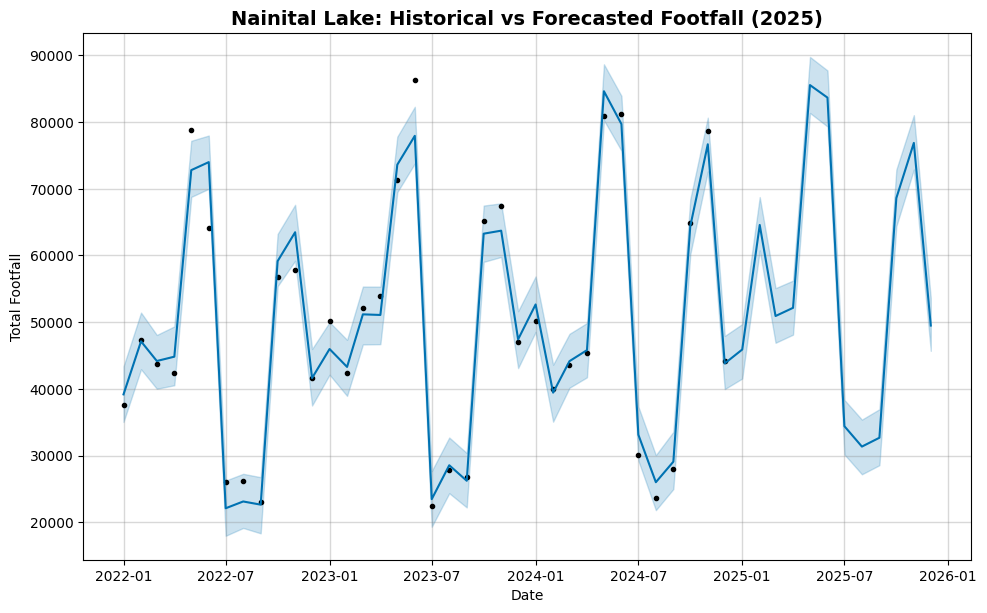

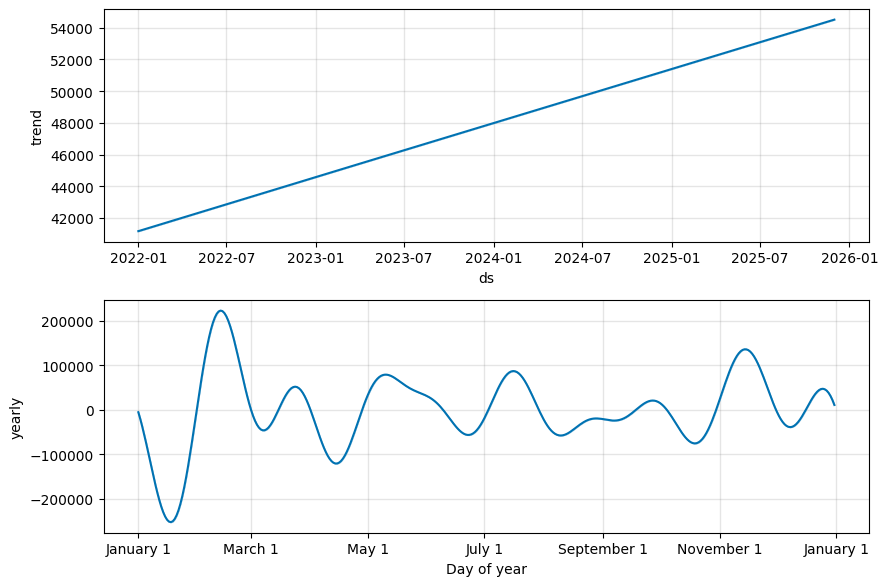

In [31]:
#   1. Plot the full forecast (Historical data + Future predictions)
fig1 = model.plot(forecast, xlabel='Date', ylabel='Total Footfall')
plt.title('Nainital Lake: Historical vs Forecasted Footfall (2025)', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.show()

# 2. Plot the underlying components (Trend and Seasonality)
fig2 = model.plot_components(forecast)
plt.show()

## **Model Evaluation for Naintal Lake**

In [33]:
import numpy as np

# 1. Merge the actual historical data with the model's predictions
# We only need the 'ds' (date) and 'yhat' (predicted value) from the forecast
merged_data = nainital_data.merge(forecast[['ds', 'yhat']], on='ds', how='left')

# 2. Calculate the Absolute Percentage Error for each month
# Formula: |Actual - Predicted| / Actual
merged_data['absolute_error'] = abs(merged_data['y'] - merged_data['yhat']) / merged_data['y']

# 3. Calculate the Mean (Average) of these errors to get MAPE
mape = merged_data['absolute_error'].mean() * 100

print(f"📊 Model Evaluation for Nainital Lake:")
print("-" * 40)
print(f"✅ Mean Absolute Percentage Error (MAPE): {mape:.2f}%")

📊 Model Evaluation for Nainital Lake:
----------------------------------------
✅ Mean Absolute Percentage Error (MAPE): 4.73%


In [35]:
print("🚀 Starting Multi-Destination Forecasting & Evaluation...\n")

# 1. Get the list of all unique destinations
destinations = data['destination'].unique()
results = []

# 2. Loop through each destination
for dest in destinations:
    # Filter data for the current destination and rename columns for Prophet
    dest_data = data[data['destination'] == dest][['date', 'total_footfall']].copy()
    dest_data.columns = ['ds', 'y']
    dest_data = dest_data.sort_values('ds')
    
    # Train the model
    model = Prophet(yearly_seasonality=True, weekly_seasonality=False)
    model.fit(dest_data)
    
    # Forecast next 12 months
    future = model.make_future_dataframe(periods=12, freq='MS')
    forecast = model.predict(future)
    # Evaluate MAPE on historical data
    merged = dest_data.merge(forecast[['ds', 'yhat']], on='ds', how='left')
    merged['abs_err'] = abs(merged['y'] - merged['yhat']) / merged['y']
    mape = merged['abs_err'].mean() * 100
    
    # Bonus: Find the predicted peak month for 2025
    future_2025 = forecast.tail(12)
    peak_row = future_2025.loc[future_2025['yhat'].idxmax()]
    peak_month = peak_row['ds'].strftime('%b %Y')
    peak_footfall = int(peak_row['yhat'])
    
    # Store results
    results.append({
        'Destination': dest,
        'MAPE (%)': round(mape, 2),
        '2025_Peak_Month': peak_month,
        '2025_Peak_Footfall': f"{peak_footfall:,}"
    })


05:06:56 - cmdstanpy - INFO - Chain [1] start processing


🚀 Starting Multi-Destination Forecasting & Evaluation...



05:06:56 - cmdstanpy - INFO - Chain [1] done processing
05:06:56 - cmdstanpy - INFO - Chain [1] start processing
05:06:56 - cmdstanpy - INFO - Chain [1] done processing
05:06:56 - cmdstanpy - INFO - Chain [1] start processing
05:06:56 - cmdstanpy - INFO - Chain [1] done processing
05:06:56 - cmdstanpy - INFO - Chain [1] start processing
05:06:57 - cmdstanpy - INFO - Chain [1] done processing
05:06:57 - cmdstanpy - INFO - Chain [1] start processing
05:06:57 - cmdstanpy - INFO - Chain [1] done processing
05:06:57 - cmdstanpy - INFO - Chain [1] start processing
05:06:57 - cmdstanpy - INFO - Chain [1] done processing
05:06:57 - cmdstanpy - INFO - Chain [1] start processing
05:06:57 - cmdstanpy - INFO - Chain [1] done processing
05:06:58 - cmdstanpy - INFO - Chain [1] start processing
05:06:58 - cmdstanpy - INFO - Chain [1] done processing


In [36]:
# 3. Convert results to a clean DataFrame and display
summary_df = pd.DataFrame(results)

print("✅ Multi-Destination Forecasting Complete!\n")
print("📊 Model Performance & 2025 Forecast Summary:")
print("-" * 65)
print(summary_df.to_string(index=False))

✅ Multi-Destination Forecasting Complete!

📊 Model Performance & 2025 Forecast Summary:
-----------------------------------------------------------------
                     Destination  MAPE (%) 2025_Peak_Month 2025_Peak_Footfall
                   Nainital Lake      4.73        May 2025             85,558
      Jim Corbett (Dhikala Zone)      4.07        Nov 2025             18,647
                Auli (Ski Slope)      6.27        Jun 2025             27,260
               Valley of Flowers      4.36        Jun 2025             18,769
         Haridwar (Har Ki Pauri)      4.48        Jun 2025            260,151
Rishikesh (Tapovan/Laxman Jhula)      5.03        Nov 2025            125,027
           Mussoorie (Mall Road)      4.50        Jun 2025             93,417
                Kedarnath Temple      3.58        Oct 2025            148,529


## **Save Model**

In [37]:
import joblib
import os

# 1. Create a folder to store our models
os.makedirs('prophet_models', exist_ok=True)

print("💾 Saving trained Prophet models...\n")

# 2. Retrain and save each model
destinations = data['destination'].unique()

for dest in destinations:
    # Prepare data
    dest_data = data[data['destination'] == dest][['date', 'total_footfall']].copy()
    dest_data.columns = ['ds', 'y']
    dest_data = dest_data.sort_values('ds')
    
    # Train
    model = Prophet(yearly_seasonality=True, weekly_seasonality=False)
    model.fit(dest_data)
    
    # Create a safe filename (replace spaces and special chars)
    safe_name = dest.replace(' ', '_').replace('(', '').replace(')', '').replace('/', '_')
    filename = f"prophet_models/{safe_name}.pkl"
    
    # Save to file
    joblib.dump(model, filename)
    print(f"✅ Saved: {filename}")

print("\n🎉 All 8 models saved successfully!")

05:09:51 - cmdstanpy - INFO - Chain [1] start processing


💾 Saving trained Prophet models...



05:09:52 - cmdstanpy - INFO - Chain [1] done processing
05:09:52 - cmdstanpy - INFO - Chain [1] start processing


✅ Saved: prophet_models/Nainital_Lake.pkl


05:09:52 - cmdstanpy - INFO - Chain [1] done processing
05:09:52 - cmdstanpy - INFO - Chain [1] start processing
05:09:52 - cmdstanpy - INFO - Chain [1] done processing


✅ Saved: prophet_models/Jim_Corbett_Dhikala_Zone.pkl
✅ Saved: prophet_models/Auli_Ski_Slope.pkl


... (4 outputs left out)

05:09:53 - cmdstanpy - INFO - Chain [1] done processing
05:09:53 - cmdstanpy - INFO - Chain [1] start processing


✅ Saved: prophet_models/Rishikesh_Tapovan_Laxman_Jhula.pkl


05:09:53 - cmdstanpy - INFO - Chain [1] done processing
05:09:53 - cmdstanpy - INFO - Chain [1] start processing
05:09:53 - cmdstanpy - INFO - Chain [1] done processing


✅ Saved: prophet_models/Mussoorie_Mall_Road.pkl
✅ Saved: prophet_models/Kedarnath_Temple.pkl

🎉 All 8 models saved successfully!
